In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
df=pd.read_csv('/content/drive/MyDrive/train.csv',usecols=['Age','Fare','Survived'])
df.sample(5)

,Survived,Age,Fare
658,0,23.0,13.0000
330,1,NaN,23.2500
513,1,54.0,59.4000
646,0,19.0,7.8958
854,0,44.0,26.0000


In [6]:
df.isnull().mean()*100

,0
Survived,0.00000
Age,19.86532
Fare,0.00000


In [7]:
X=df[['Age','Fare']]
Y=df['Survived']

In [8]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [9]:
df.shape

(891, 3)

In [10]:
X_train

,Age,Fare
331,45.5,28.5000
733,23.0,13.0000
382,32.0,7.9250
704,26.0,7.8542
813,6.0,31.2750
...,...,...
106,21.0,7.6500
270,NaN,31.0000
860,41.0,14.1083
435,14.0,120.0000


In [11]:
X_test

,Age,Fare
709,NaN,15.2458
439,31.0,10.5000
840,20.0,7.9250
720,6.0,33.0000
39,14.0,11.2417
...,...,...
433,17.0,7.1250
773,NaN,7.2250
25,38.0,31.3875
84,17.0,10.5000


In [12]:
X_train['Age_imputed']=X_train['Age']
X_test['Age_imputed']=X_test['Age']

In [15]:
X_train.loc[X_train['Age_imputed'].isnull(), 'Age_imputed'] = (
    X_train['Age'].dropna()
    .sample(X_train['Age_imputed'].isnull().sum())
    .values
)

X_test.loc[X_test['Age_imputed'].isnull(), 'Age_imputed'] = (
    X_train['Age'].dropna()
    .sample(X_test['Age_imputed'].isnull().sum())
    .values
)

Age imputed column have only those values which age column has

In [17]:
X_train['Age_imputed'][X_train['Age_imputed'].isnull()]

,Age_imputed


In [31]:
# drop missing values

# randomly selecting age values for missing values
sampled_ages=X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values



In [32]:
X_train.head()

,Age,Fare,Age_imputed
331,45.5,28.5000,45.5
733,23.0,13.0000,23.0
382,32.0,7.9250,32.0
704,26.0,7.8542,26.0
813,6.0,31.2750,6.0


There will be no difference between distribution

* In tree based algo the difference between distribution come

* But in linear algos no major difference comes

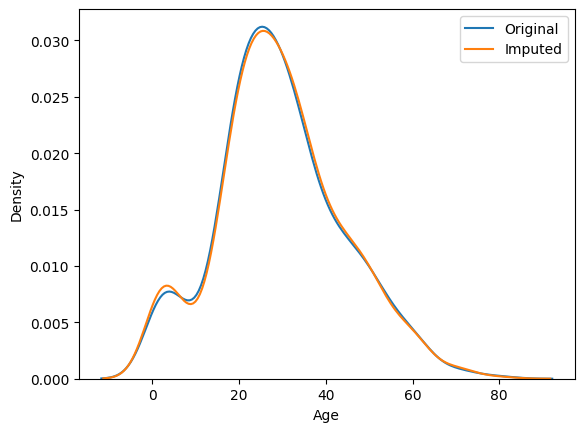

In [33]:
sns.kdeplot(X_train['Age'],label='Original')
sns.kdeplot(X_train['Age_imputed'],label='Imputed')
plt.legend()
plt.show()

Talking about the variance

No major difference in variance

In [34]:
print('Original variable variance: ',X_train['Age'].var())
print('Variance after random imputation: ',X_train['Age_imputed'].var())

Original variable variance:  210.2517072477438
Variance after random imputation:  212.71145570884525


There comes a difference between covariance

In [35]:
X_train[['Fare','Age','Age_imputed']].cov()

,Fare,Age,Age_imputed
Fare,2700.831981,71.580633,54.481440
Age,71.580633,210.251707,210.251707
Age_imputed,54.481440,210.251707,212.711456


No major difference between outliers

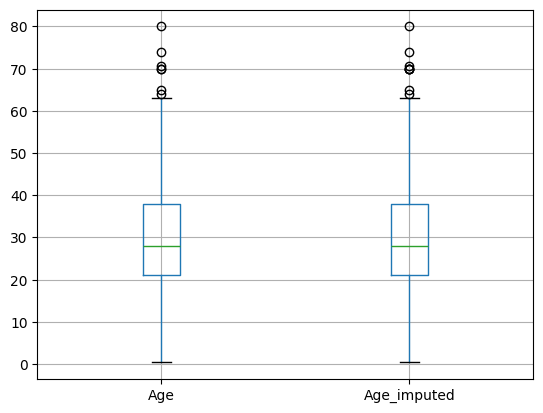

In [38]:
X_train[['Age','Age_imputed']].boxplot()
plt.show()

In [40]:
observation = X_train.iloc[0]

In [41]:
sampled_value=X_train['Age'].dropna().sample(1,random_state=int(observation['Fare']))

In [45]:
data=pd.read_csv('/content/drive/MyDrive/house-train.csv',usecols=['GarageQual','FireplaceQu','SalePrice'])
data.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [46]:
data.isnull().mean()*100

,0
FireplaceQu,47.260274
GarageQual,5.547945
SalePrice,0.000000


In [47]:
X=data
Y=data['SalePrice']

In [48]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=2)

In [49]:
X_train['GarageQual_imputed']=X_train['GarageQual']
X_test['GarageQual_imputed']=X_test['GarageQual']

X_train['FireplaceQu_imputed']=X_train['FireplaceQu']
X_test['FireplaceQu_imputed']=X_test['FireplaceQu']

In [50]:
X_train.sample(5)

,FireplaceQu,GarageQual,SalePrice,GarageQual_imputed,FireplaceQu_imputed
276,NaN,TA,201000,TA,NaN
222,TA,TA,179900,TA,TA
644,Gd,TA,370878,TA,Gd
544,Gd,TA,179665,TA,Gd
129,NaN,TA,150000,TA,NaN


In [51]:
X_train.loc[X_train['GarageQual_imputed'].isnull(), 'GarageQual_imputed'] = (
    X_train['GarageQual'].dropna()
    .sample(X_train['GarageQual_imputed'].isnull().sum())
    .values
)

X_test.loc[X_test['GarageQual_imputed'].isnull(), 'GarageQual_imputed'] = (
    X_train['GarageQual'].dropna()
    .sample(X_test['GarageQual_imputed'].isnull().sum())
    .values
)

In [52]:
X_train.loc[X_train['FireplaceQu_imputed'].isnull(), 'FireplaceQu_imputed'] = (
    X_train['FireplaceQu'].dropna()
    .sample(X_train['FireplaceQu_imputed'].isnull().sum())
    .values
)

X_test.loc[X_test['FireplaceQu_imputed'].isnull(), 'FireplaceQu_imputed'] = (
    X_train['FireplaceQu'].dropna()
    .sample(X_test['FireplaceQu_imputed'].isnull().sum())
    .values
)

To know the frequency of data before and after imputation

In [54]:
temp=pd.concat(
[
    X_train['GarageQual'].value_counts()/len(X_train['GarageQual'].dropna()),
    X_train['GarageQual_imputed'].value_counts()/len(X_train)
],axis=1)
temp.columns=['Original','Imputed']

In [55]:
temp

,Original,Imputed
TA,0.951043,0.949486
Fa,0.037171,0.039384
Gd,0.009973,0.009418
Po,0.000907,0.000856
Ex,0.000907,0.000856


In [56]:
temp2=pd.concat(
[
    X_train['FireplaceQu'].value_counts()/len(X_train['FireplaceQu'].dropna()),
    X_train['FireplaceQu_imputed'].value_counts()/len(X_train)
],axis=1)
temp2.columns=['Original','Imputed']

In [57]:
temp2

,Original,Imputed
Gd,0.494272,0.497432
TA,0.412439,0.409247
Fa,0.040917,0.041096
Po,0.027823,0.027397
Ex,0.024550,0.024829


In [59]:
print(X_train.columns.tolist())

['FireplaceQu', 'GarageQual', 'SalePrice', 'GarageQual_imputed', 'FireplaceQu_imputed']


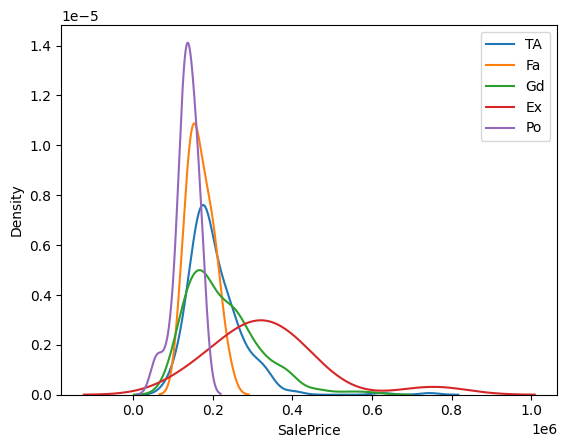

In [64]:
for category in X_train['FireplaceQu'].dropna().unique():
  sns.kdeplot(X_train[X_train['FireplaceQu']==category]['SalePrice'],label=category)
plt.legend()
plt.show()

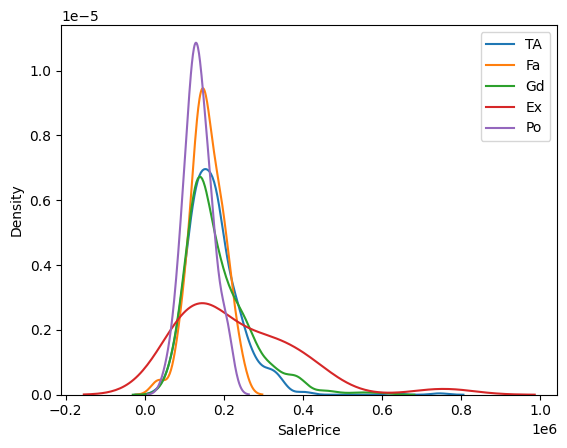

In [65]:
for category in X_train['FireplaceQu_imputed'].dropna().unique():
  sns.kdeplot(X_train[X_train['FireplaceQu_imputed']==category]['SalePrice'],label=category)
plt.legend()
plt.show()